# Modellierung

## Init

In [5]:
import pandas as pd
import matplotlib.pyplot as plt


# Load the dataset
file_path = '../../data/processed/sickness_table.csv'
df = pd.read_csv(file_path, index_col=0)

# Convert date column to datetime
df.index = pd.to_datetime(df.index)

# Set daily frequency
df = df.asfreq('d')

# Datenselektierung

In [6]:
df.head()

,n_sick,calls,n_duty,n_sby,sby_need,dafted,is_holiday,tavg,unix_ts_date,needed_personal,calls_per_duty,call_stress,sby_used_percent
date,,,,,,,,,,,,,
2016-04-01,73,8154.0,1700,90,4.0,0.0,False,8.3,1459468800,1631.0,4.796471,4.785211,4.444444
2016-04-02,64,8526.0,1700,90,70.0,0.0,False,9.9,1459555200,1706.0,5.015294,4.816949,77.777778
2016-04-03,68,8088.0,1700,90,0.0,0.0,False,13.1,1459641600,1632.0,4.757647,4.757647,0.000000
2016-04-04,71,7044.0,1700,90,0.0,0.0,False,15.2,1459728000,1629.0,4.143529,4.143529,0.000000
2016-04-05,63,7236.0,1700,90,0.0,0.0,False,16.0,1459814400,1637.0,4.256471,4.256471,0.000000


In [7]:
target_column = "calls"

# Time series modeling

## SARIMAX in loop

In [9]:
import pandas as pd
import numpy as np
import itertools
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error

# Funktionsdefinition zur Optimierung
def optimize_sarimax(train, test, exog_train, exog_test, p_range, d_range, q_range, P_range, D_range, Q_range, s_range):
    results = []
    
    # Alle möglichen Parameterkombinationen durchlaufen
    for p, d, q, P, D, Q, s in itertools.product(p_range, d_range, q_range, P_range, D_range, Q_range, s_range):
        try:
            # Modellierung
            model = SARIMAX(train[target_column], 
                            exog=exog_train.astype(float),
                            order=(p, d, q),
                            seasonal_order=(P, D, Q, s),
                            enforce_stationarity=False,
                            enforce_invertibility=False)
            sarimax_result = model.fit(disp=False)
            
            # Vorhersage
            forecast = sarimax_result.get_forecast(steps=len(test), exog=exog_test.astype(float))
            forecasted_values = forecast.predicted_mean
            
            # Metriken berechnen
            mae = mean_absolute_error(test[target_column], forecasted_values)
            mape = mean_absolute_percentage_error(test[target_column], forecasted_values) * 100
            r2 = r2_score(test[target_column], forecasted_values)
            
            #print(f"p: {p}, d: {d}, q: {q}, P: {P}, D: {D}, Q: {Q}, s: {s} => MAE: {mae}, MAPE: {mape}%, R2: {r2}")
            
            # Speichern der Ergebnisse in der Liste
            results.append({'p': p, 'd': d, 'q': q, 'P': P, 'D': D, 'Q': Q, 's': s, 
                            'MAE': mae, 'MAPE': mape, 'R2': r2})
                
        except Exception as e:
            print(f"Error fitting SARIMAX model with parameters ({p}, {d}, {q}, {P}, {D}, {Q}, {s}): {e}")
            continue
    
    # Umwandeln der Ergebnisse in einen DataFrame
    results_df = pd.DataFrame(results)
    
    return results_df

# Definition der Parameterbereiche
p_range = range(0, 3)#3)
d_range = range(0, 3)#3)
q_range = range(0, 3)#3)
P_range = range(0, 2)#2)
D_range = range(0, 2)#2)
Q_range = range(0, 2)#2)
s_range = range(0, 7) # [7]

# Sicherstellen, dass der Index als DatetimeIndex formatiert ist
data = df.copy(deep=True)

# Frequenz auf tägliche Intervalle setzen ('D' steht für 'Daily')
data = data.asfreq('D')

# Aufteilung der Daten in Trainings- und Testdatensätze (20% Testdaten)
train_size = int(len(data) * 0.8)
train, test = data.iloc[:train_size], data.iloc[train_size:]

# Definieren der exogenen Variablen für Training und Test
exog_columns = ['tavg']

exog_train = train[exog_columns]
exog_test = test[exog_columns]

# Optimierung starten
results_df = optimize_sarimax(train, test, exog_train, exog_test, p_range, d_range, q_range, P_range, D_range, Q_range, s_range)

Error fitting SARIMAX model with parameters (0, 0, 0, 0, 0, 0, 1): Seasonal periodicity must be greater than 1.
Error fitting SARIMAX model with parameters (0, 0, 0, 0, 0, 1, 0): Must include nonzero seasonal periodicity if including seasonal AR, MA, or differencing.
Error fitting SARIMAX model with parameters (0, 0, 0, 0, 0, 1, 1): Seasonal periodicity must be greater than 1.
Error fitting SARIMAX model with parameters (0, 0, 0, 0, 1, 0, 0): Must include nonzero seasonal periodicity if including seasonal AR, MA, or differencing.
Error fitting SARIMAX model with parameters (0, 0, 0, 0, 1, 0, 1): Seasonal periodicity must be greater than 1.
Error fitting SARIMAX model with parameters (0, 0, 0, 0, 1, 1, 0): Must include nonzero seasonal periodicity if including seasonal AR, MA, or differencing.
Error fitting SARIMAX model with parameters (0, 0, 0, 0, 1, 1, 1): Seasonal periodicity must be greater than 1.
Error fitting SARIMAX model with parameters (0, 0, 0, 1, 0, 0, 0): Must include nonz

/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Error fitting SARIMAX model with parameters (0, 0, 0, 1, 1, 0, 0): Must include nonzero seasonal periodicity if including seasonal AR, MA, or differencing.
Error fitting SARIMAX model with parameters (0, 0, 0, 1, 1, 0, 1): Seasonal periodicity must be greater than 1.
Error fitting SARIMAX model with parameters (0, 0, 0, 1, 1, 1, 0): Must include nonzero seasonal periodicity if including seasonal AR, MA, or differencing.
Error fitting SARIMAX model with parameters (0, 0, 0, 1, 1, 1, 1): Seasonal periodicity must be greater than 1.
Error fitting SARIMAX model with parameters (0, 0, 1, 0, 0, 0, 1): Seasonal periodicity must be greater than 1.
Error fitting SARIMAX model with parameters (0, 0, 1, 0, 0, 1, 0): Must include nonzero seasonal periodicity if including seasonal AR, MA, or differencing.
Error fitting SARIMAX model with parameters (0, 0, 1, 0, 0, 1, 1): Seasonal periodicity must be greater than 1.


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Error fitting SARIMAX model with parameters (0, 0, 1, 0, 1, 0, 0): Must include nonzero seasonal periodicity if including seasonal AR, MA, or differencing.
Error fitting SARIMAX model with parameters (0, 0, 1, 0, 1, 0, 1): Seasonal periodicity must be greater than 1.
Error fitting SARIMAX model with parameters (0, 0, 1, 0, 1, 1, 0): Must include nonzero seasonal periodicity if including seasonal AR, MA, or differencing.
Error fitting SARIMAX model with parameters (0, 0, 1, 0, 1, 1, 1): Seasonal periodicity must be greater than 1.
Error fitting SARIMAX model with parameters (0, 0, 1, 1, 0, 0, 0): Must include nonzero seasonal periodicity if including seasonal AR, MA, or differencing.
Error fitting SARIMAX model with parameters (0, 0, 1, 1, 0, 0, 1): Seasonal periodicity must be greater than 1.


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


... (174 outputs left out)

Error fitting SARIMAX model with parameters (2, 2, 2, 1, 1, 0, 0): Must include nonzero seasonal periodicity if including seasonal AR, MA, or differencing.
Error fitting SARIMAX model with parameters (2, 2, 2, 1, 1, 0, 1): Seasonal periodicity must be greater than 1.
Error fitting SARIMAX model with parameters (2, 2, 2, 1, 1, 0, 2): Invalid model: autoregressive lag(s) {2} are in both the seasonal and non-seasonal autoregressive components.


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


Error fitting SARIMAX model with parameters (2, 2, 2, 1, 1, 1, 0): Must include nonzero seasonal periodicity if including seasonal AR, MA, or differencing.
Error fitting SARIMAX model with parameters (2, 2, 2, 1, 1, 1, 1): Seasonal periodicity must be greater than 1.
Error fitting SARIMAX model with parameters (2, 2, 2, 1, 1, 1, 2): Invalid model: autoregressive lag(s) {2} are in both the seasonal and non-seasonal autoregressive components.


/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


In [10]:

# Ergebnisse sortieren (z.B. nach MAE)
sorted_results_df = results_df.sort_values(by='MAE').reset_index(drop=True)
display(sorted_results_df)

,p,d,q,P,D,Q,s,MAE,MAPE,R2
0,2,0,2,1,0,0,3,9.965030e+02,12.243552,1.534011e-01
1,1,1,2,1,1,1,4,9.994910e+02,12.421037,1.423391e-01
2,2,2,1,1,1,1,3,9.998606e+02,12.563984,1.147033e-01
3,1,1,2,1,1,1,6,1.000586e+03,12.339745,1.436096e-01
4,0,1,2,1,1,1,6,1.001265e+03,12.320719,1.439026e-01
...,...,...,...,...,...,...,...,...,...,...
1036,0,2,0,1,1,0,3,6.530508e+06,73695.243169,-4.513154e+07
1037,0,2,0,1,1,0,2,8.181817e+06,92302.750461,-7.106545e+07
1038,0,2,0,0,1,0,3,1.050301e+07,118474.871763,-1.172571e+08
1039,1,2,0,0,1,0,2,1.270550e+07,143314.662722,-1.716459e+08


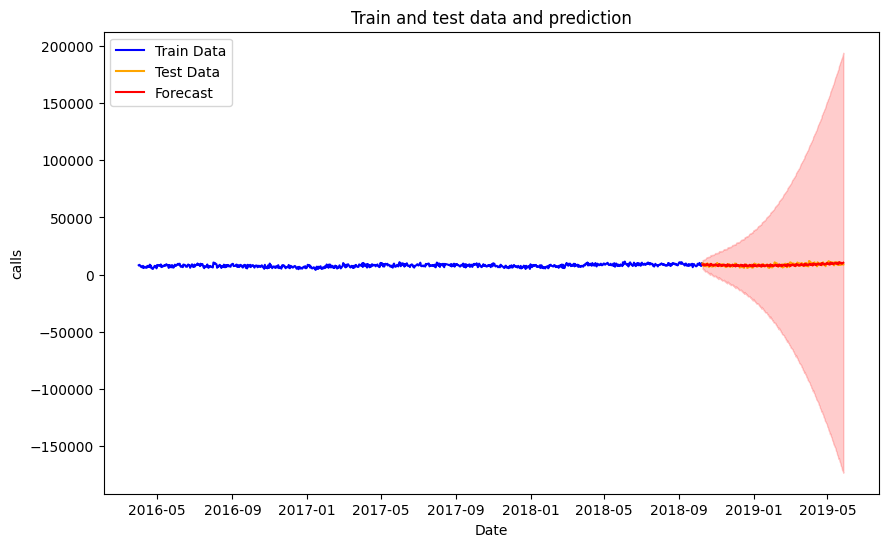

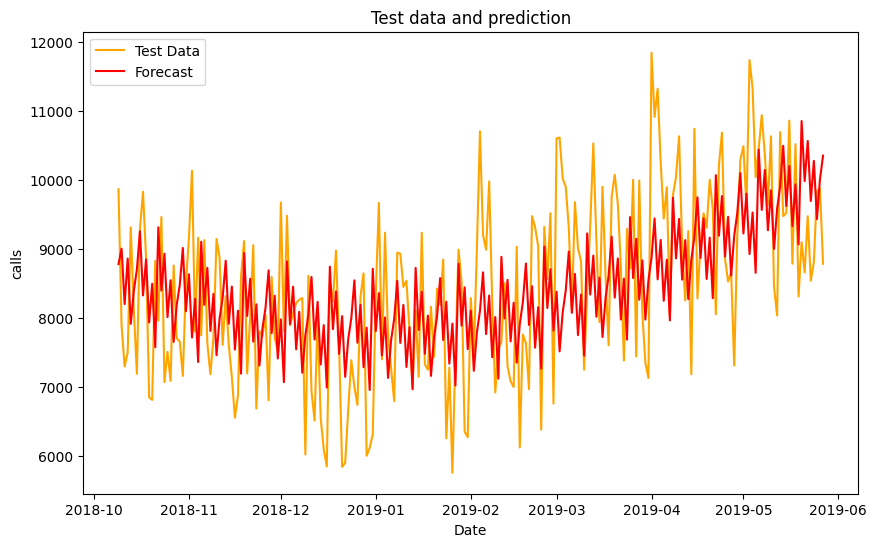

Model MAPE: 11.824049654242828%, Model MAE: 976.9443431291077, R2 Score: 0.1914014599415802


In [7]:

# Beste Parameter basierend auf dem minimalen MAE oder maximalen R2 auswählen
best_params = sorted_results_df.iloc[0]

p, d, q = int(best_params['p']), int(best_params['d']), int(best_params['q'])
P, D, Q, s = int(best_params['P']), int(best_params['D']), int(best_params['Q']), int(best_params['s'])

# Best set so far
p, d, q = 0, 2, 2
P, D, Q, s = 1, 1, 0, 2

p, d, q = 0, 2, 2
P, D, Q, s = 1, 1, 0, 2


# Modell mit den besten Parametern trainieren
model = SARIMAX(train[target_column], 
                exog=exog_train.astype(float),
                order=(p, d, q), 
                seasonal_order=(P, D, Q, s), 
                enforce_stationarity=False,
                enforce_invertibility=False)
sarimax_result = model.fit(disp=False)

# Vorhersage mit den besten Parametern
forecast = sarimax_result.get_forecast(steps=len(test), exog=exog_test.astype(float))
forecast_ci = forecast.conf_int()

y_pred = forecast.predicted_mean

# Plotten der Ergebnisse
plt.figure(figsize=(10, 6))
plt.plot(train.index, train[target_column], label='Train Data', color='blue')
plt.plot(test.index, test[target_column], label='Test Data', color='orange')
plt.plot(test.index, y_pred, label='Forecast', color='red')
plt.fill_between(test.index, 
                 forecast_ci.iloc[:, 0], 
                 forecast_ci.iloc[:, 1], color='red', alpha=0.2)
plt.title('Train and test data and prediction')
plt.xlabel('Date')
plt.ylabel(target_column)
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(test.index, test[target_column], label='Test Data', color='orange')
plt.plot(test.index, y_pred, label='Forecast', color='red')
#plt.fill_between(test.index, 
#                 forecast_ci.iloc[:, 0], 
#                 forecast_ci.iloc[:, 1], color='red', alpha=0.2)
plt.title('Test data and prediction')
plt.xlabel('Date')
plt.ylabel(target_column)
plt.legend()
plt.show()


print(f'Model MAPE: {mean_absolute_percentage_error(test[target_column], y_pred)* 100}%, Model MAE: {mean_absolute_error(test[target_column], y_pred)}, R2 Score: {r2_score(test[target_column], y_pred)}')


In [13]:
validation_df = test.copy(deep=True)

validation_df = validation_df.rename(columns={"calls" : "orig_calls", "sby_need" : "orig_sby_need"})

validation_df["calls"] = sarimax_result.get_forecast(steps=len(test), exog=exog_test.astype(float)).predicted_mean

validation_df["sby_need_new"] = validation_df.apply(lambda row: max(0, (row.calls / 4.8) - row.n_duty + row.n_sby) , axis=1)
validation_df["sby_need_based_on_orig_calls"] = validation_df.apply(lambda row: max(0,(row.orig_calls / 4.8) - row.n_duty + row.n_sby), axis=1)

validation_df["sby_need_diff"] = validation_df.apply(lambda row:  row.sby_need_new - row.orig_sby_need, axis=1)

display(validation_df[["orig_calls", "calls", "sby_need_based_on_orig_calls", "sby_need_new", "orig_sby_need", "sby_need_diff" ]])
display(validation_df[["orig_calls", "calls", "sby_need_based_on_orig_calls", "sby_need_new", "orig_sby_need", "sby_need_diff" ]].describe())

,orig_calls,calls,sby_need_based_on_orig_calls,sby_need_new,orig_sby_need,sby_need_diff
date,,,,,,
2018-10-09,9870.0,8784.829567,246.25,20.172826,171.0,-150.827174
2018-10-10,7896.0,9009.096975,0.00,66.895203,0.0,66.895203
2018-10-11,7302.0,8205.652715,0.00,0.000000,0.0,0.000000
2018-10-12,7506.0,8865.484414,0.00,36.975920,0.0,36.975920
2018-10-13,9318.0,7919.237467,131.25,0.000000,57.0,-57.000000
...,...,...,...,...,...,...
2019-05-23,8544.0,9699.976114,0.00,210.828357,0.0,210.828357
2019-05-24,8814.0,10282.534338,26.25,332.194654,0.0,332.194654
2019-05-25,9846.0,9436.783915,241.25,155.996649,146.0,9.996649


,orig_calls,calls,sby_need_based_on_orig_calls,sby_need_new,orig_sby_need,sby_need_diff
count,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000
mean,8473.532468,8433.535443,90.638528,45.798588,53.554113,-7.755525
std,1297.897640,803.504672,142.549518,90.720014,106.556967,112.376130
min,5760.000000,6959.544730,0.000000,0.000000,0.000000,-515.948692
25%,7509.000000,7866.590335,0.000000,0.000000,0.000000,0.000000
50%,8502.000000,8330.893563,0.000000,0.000000,0.000000,0.000000
75%,9336.000000,8883.243975,135.000000,40.675828,56.500000,0.000000
max,11850.000000,10859.809610,658.750000,452.460336,555.000000,447.460336


In [16]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
from typing import List, Optional

def calculate_regression_metrics(y_test : List, y_pred : List, print_results : bool = False) -> dict:
    results= {
        'MAE': float(mean_absolute_error(y_test, y_pred)),
        'MSE': float(mean_squared_error(y_test, y_pred)),
        'R2':float( r2_score(y_test, y_pred)),
        'MAPE': float(mean_absolute_percentage_error(y_test, y_pred)),
    }

    if print_results:
        print(f'Results: - ' + ', '.join(f'{key}: {value}' for key, value in results.items()))

    return results

calculate_regression_metrics(validation_df["orig_sby_need"], validation_df["sby_need_new"], print_results=True)


Results: - MAE: 58.12160506101319, MSE: 12633.874365530026, R2: -0.11752434940694578, MAPE: 7.128306068164546e+16


{'MAE': 58.12160506101319,
 'MSE': 12633.874365530026,
 'R2': -0.11752434940694578,
 'MAPE': 7.128306068164546e+16}

## Auto SARIMAX

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,0,1)[2] intercept   : AIC=15341.970, Time=0.71 sec
 ARIMA(0,1,0)(0,0,0)[2] intercept   : AIC=15759.509, Time=0.02 sec
 ARIMA(1,1,0)(1,0,0)[2] intercept   : AIC=15470.708, Time=0.09 sec
 ARIMA(0,1,1)(0,0,1)[2] intercept   : AIC=15365.892, Time=0.36 sec
 ARIMA(0,1,0)(0,0,0)[2]             : AIC=15757.512, Time=0.01 sec
 ARIMA(1,1,1)(0,0,1)[2] intercept   : AIC=15342.994, Time=0.57 sec
 ARIMA(1,1,1)(1,0,0)[2] intercept   : AIC=15343.266, Time=0.52 sec
 ARIMA(1,1,1)(2,0,1)[2] intercept   : AIC=15348.476, Time=0.90 sec
 ARIMA(1,1,1)(1,0,2)[2] intercept   : AIC=15345.443, Time=0.93 sec
 ARIMA(1,1,1)(0,0,0)[2] intercept   : AIC=15345.386, Time=0.32 sec
 ARIMA(1,1,1)(0,0,2)[2] intercept   : AIC=15344.231, Time=0.82 sec
 ARIMA(1,1,1)(2,0,0)[2] intercept   : AIC=15344.490, Time=0.86 sec
 ARIMA(1,1,1)(2,0,2)[2] intercept   : AIC=15347.880, Time=1.35 sec
 ARIMA(0,1,1)(1,0,1)[2] intercept   : AIC=15362.773, Time=0.65 sec
 ARIMA(1,1,0)(1,0,1

/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)


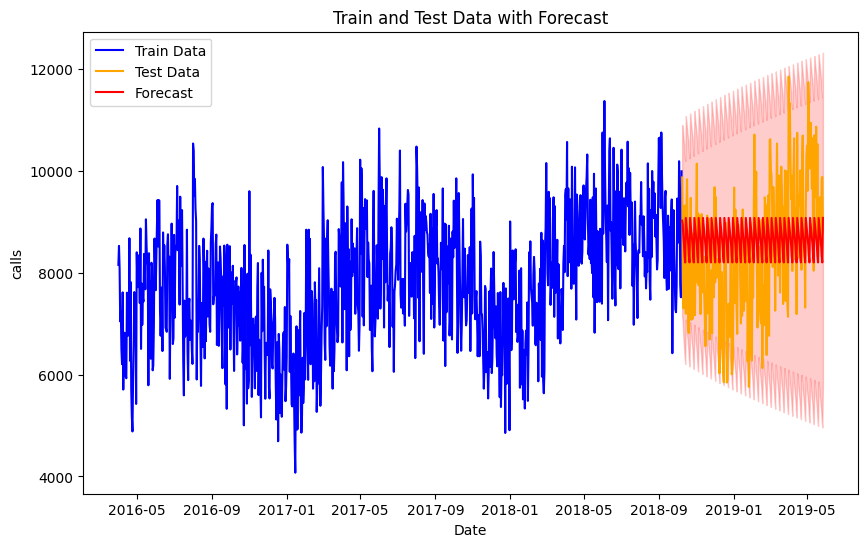

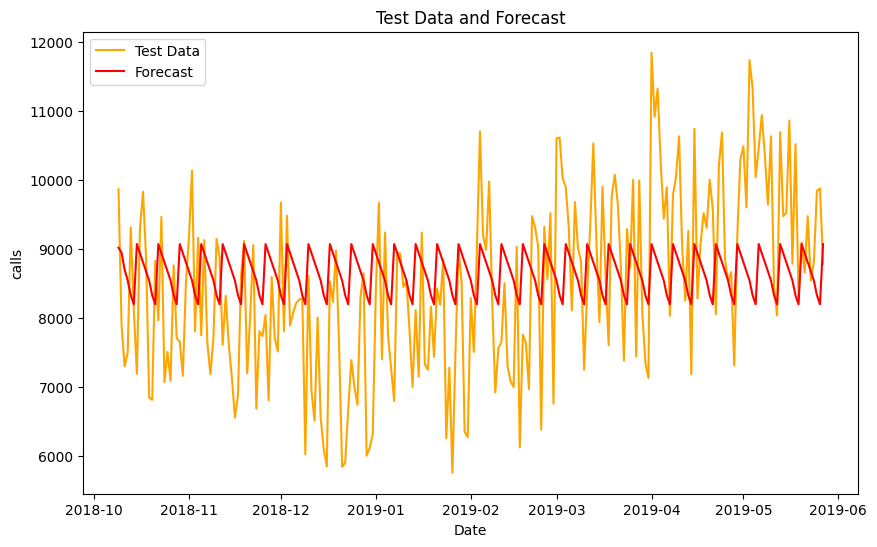

Model MAPE: 13.293876591866653%, Model MAE: 1067.00247600251, R2 Score: 0.018806156968088517


In [85]:
import pandas as pd
import matplotlib.pyplot as plt
from pmdarima import auto_arima
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, r2_score


train_size = int(len(df) * 0.8)
train, test = df.iloc[:train_size], df.iloc[train_size:]

# Definieren der exogenen Variablen für Training und Test
exog_train = train[['is_weekend', 'is_holiday', 'day_of_week']]
exog_test = test[['is_weekend', 'is_holiday', 'day_of_week']]

# Automatische Auswahl der besten SARIMAX-Parameter
auto_model = auto_arima(
    train['calls'], 
    exogenous=exog_train.astype(float),
    seasonal=True, 
    m=12,  # Die saisonale Periode (s)
    trace=True, 
    error_action='ignore', 
    suppress_warnings=True,
    stepwise=True
)


# Die besten Parameter extrahieren
best_params = auto_model.get_params()
p, d, q = best_params['order']
P, D, Q, s = best_params['seasonal_order']

# Modell mit den besten Parametern trainieren
model = SARIMAX(train['calls'], 
                exog=exog_train.astype(float),
                order=(p, d, q), 
                seasonal_order=(P, D, Q, s), 
                enforce_stationarity=False,
                enforce_invertibility=False)
sarimax_result = model.fit(disp=False)

# Vorhersage mit den besten Parametern
forecast = sarimax_result.get_forecast(steps=len(test), exog=exog_test.astype(float))
forecast_ci = forecast.conf_int()

# Plotten der Ergebnisse
plt.figure(figsize=(10, 6))
plt.plot(train.index, train['calls'], label='Train Data', color='blue')
plt.plot(test.index, test['calls'], label='Test Data', color='orange')
plt.plot(test.index, forecast.predicted_mean, label='Forecast', color='red')
plt.fill_between(test.index, 
                 forecast_ci.iloc[:, 0], 
                 forecast_ci.iloc[:, 1], color='red', alpha=0.2)
plt.title('Train and Test Data with Forecast')
plt.xlabel('Date')
plt.ylabel('calls')
plt.legend()
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(test.index, test['calls'], label='Test Data', color='orange')
plt.plot(test.index, forecast.predicted_mean, label='Forecast', color='red')
plt.title('Test Data and Forecast')
plt.xlabel('Date')
plt.ylabel('calls')
plt.legend()
plt.show()

# Leistungskennzahlen berechnen
mape = mean_absolute_percentage_error(test['calls'], forecast.predicted_mean) * 100
mae = mean_absolute_error(test['calls'], forecast.predicted_mean)
r2 = r2_score(test['calls'], forecast.predicted_mean)

print(f'Model MAPE: {mape}%, Model MAE: {mae}, R2 Score: {r2}')


## PMD Auto ARIMA

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(1,1,1)[12]             : AIC=inf, Time=3.97 sec
 ARIMA(0,1,0)(0,1,0)[12]             : AIC=16243.388, Time=0.04 sec
 ARIMA(1,1,0)(1,1,0)[12]             : AIC=15786.056, Time=1.26 sec
 ARIMA(0,1,1)(0,1,1)[12]             : AIC=inf, Time=1.56 sec
 ARIMA(1,1,0)(0,1,0)[12]             : AIC=16075.541, Time=0.09 sec
 ARIMA(1,1,0)(2,1,0)[12]             : AIC=15642.231, Time=3.39 sec
 ARIMA(1,1,0)(3,1,0)[12]             : AIC=15572.226, Time=7.31 sec
 ARIMA(1,1,0)(3,1,1)[12]             : AIC=inf, Time=17.79 sec
 ARIMA(1,1,0)(2,1,1)[12]             : AIC=inf, Time=4.79 sec
 ARIMA(0,1,0)(3,1,0)[12]             : AIC=15773.319, Time=1.58 sec
 ARIMA(2,1,0)(3,1,0)[12]             : AIC=15503.768, Time=8.90 sec
 ARIMA(2,1,0)(2,1,0)[12]             : AIC=15570.438, Time=4.85 sec
 ARIMA(2,1,0)(3,1,1)[12]             : AIC=inf, Time=16.32 sec
 ARIMA(2,1,0)(2,1,1)[12]             : AIC=inf, Time=9.39 sec
 ARIMA(3,1,0)(3,1,0)[12]             : 

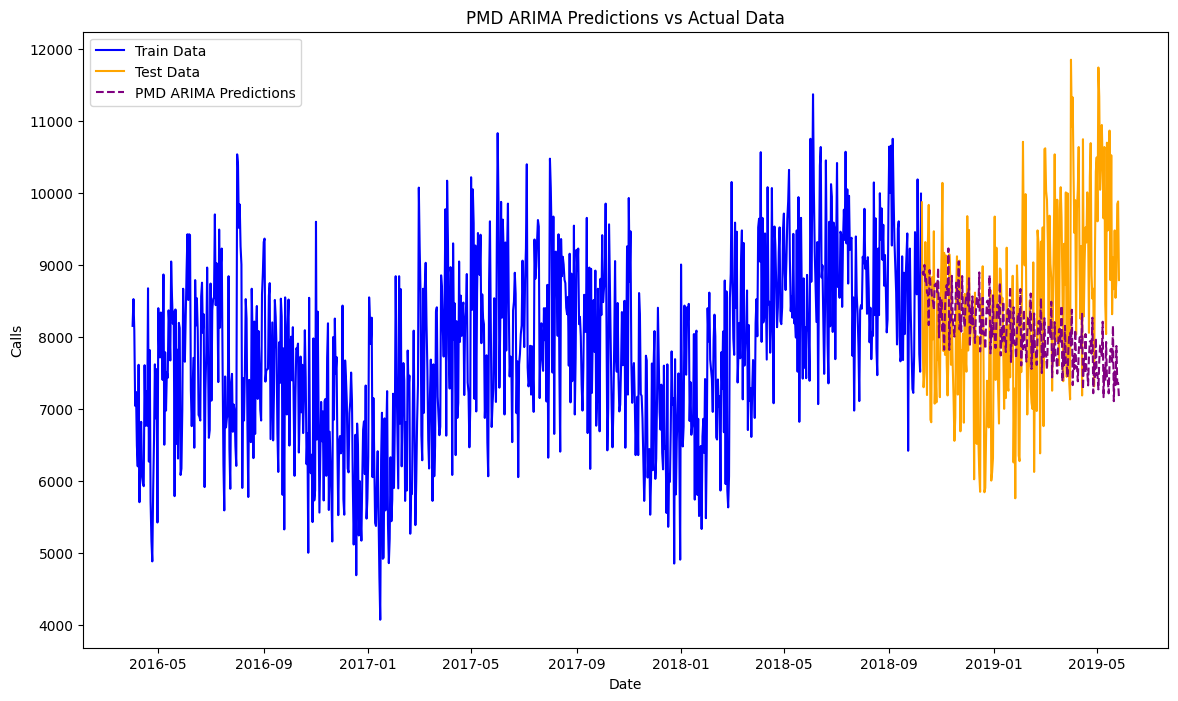

In [78]:
from pmdarima.arima import auto_arima # nur nutzbar in venv wegen inkompatibilität mit aktueller numpy version


# Split data into training and testing datasets
train_size = int(len(df) * 0.8)
train, test = df['calls'][:train_size], df['calls'][train_size:]

model = auto_arima(train, seasonal=True, m=12,  # m=12 für monatliche Saisonalität
                   start_p=1, start_q=1,
                   max_p=3, max_q=3, #max vorher 3 #damit nur knapp 2min gebraucht
                   start_P=1, start_Q=1,
                   max_P=3, max_Q=3,
                   d=1, D=1,
                   trace=True,  # Trace auf True setzen, um den Fortschritt zu sehen
                   error_action='ignore',  
                   suppress_warnings=True, 
                   stepwise=True)

pmd_forecast = model.predict(n_periods=len(test))


plt.figure(figsize=(14, 8))

# Plot Train and Test Data
plt.plot(train.index, train, label='Train Data', color='blue')
plt.plot(test.index, test, label='Test Data', color='orange')

plt.plot(test.index, pmd_forecast, label='PMD ARIMA Predictions', color='purple', linestyle='--')

plt.legend()
plt.title('PMD ARIMA Predictions vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Calls')
plt.show()


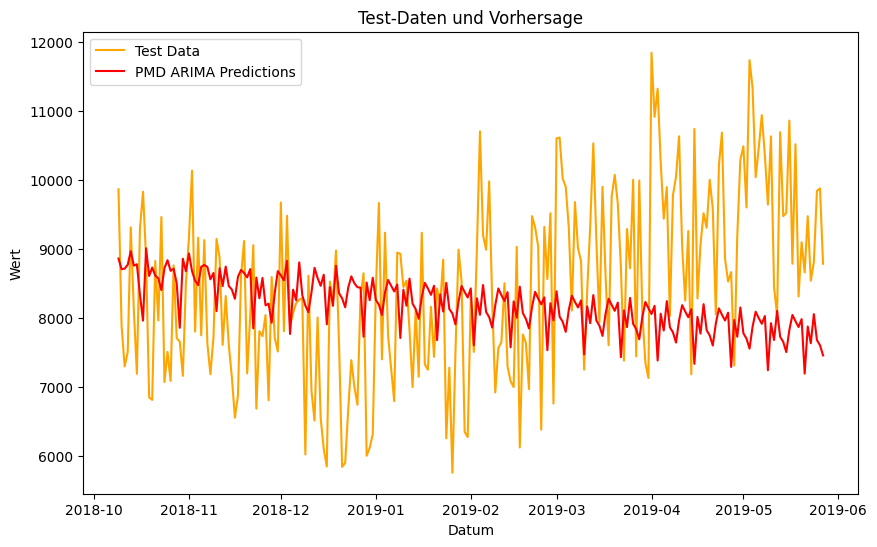

Model MAPE: 14.594187779324184%, Model MAE: 1229.9249460924557, R2 Score: -0.3316462698762406


In [32]:
plt.figure(figsize=(10, 6))
plt.plot(test.index, test, label='Test Data', color='orange')

plt.plot(test.index, pmd_forecast, label='PMD ARIMA Predictions', color='red')
plt.title('Test-Daten und Vorhersage')
plt.xlabel('Datum')
plt.ylabel('Wert')
plt.legend()
plt.show()

print(f'Model MAPE: {mean_absolute_percentage_error(test, pmd_forecast)* 100}%, Model MAE: {mean_absolute_error(test, pmd_forecast)}, R2 Score: {r2_score(test, pmd_forecast)}')


## Exponential Smoothing

/usr/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
/usr/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
/usr/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency D will be used.
  self._init_dates(dates, freq)
/usr/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: Conver

Mean Squared Error (Simple Exponential Smoothing): 1722015.7817197258
Mean Squared Error (Holt’s Linear Trend Model): 1745586.6554827087
Mean Squared Error (Holt-Winters Seasonal Model): 1701504.869461197


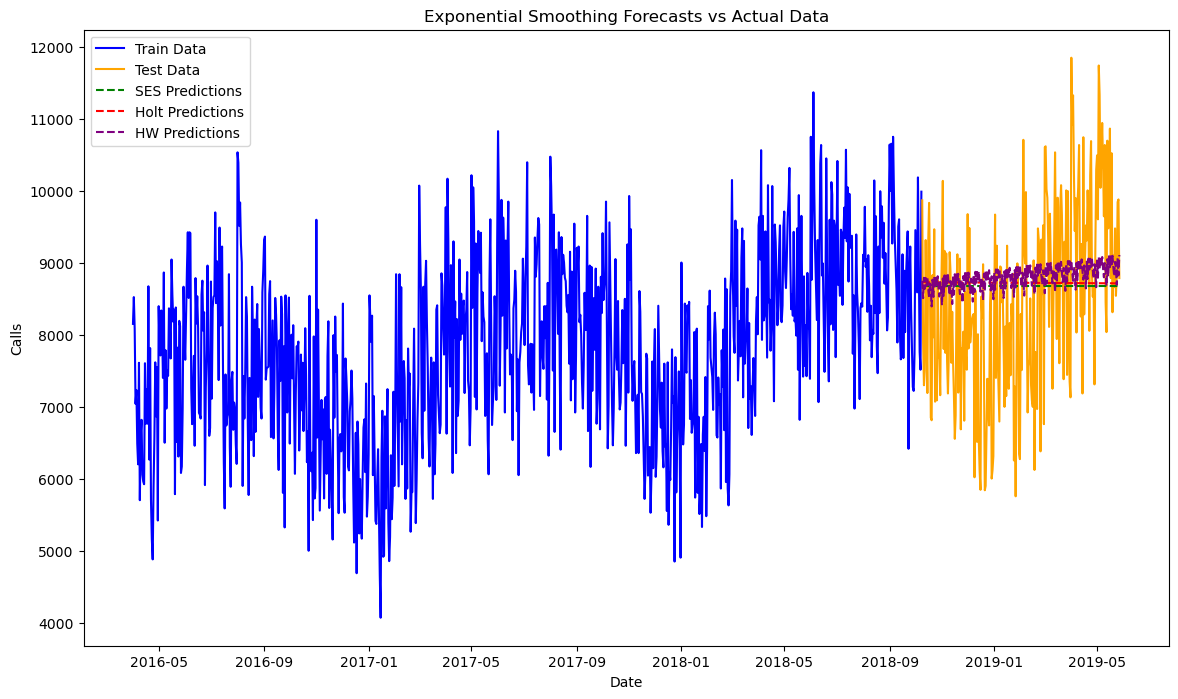

In [49]:
import numpy as np
from statsmodels.tsa.api import ExponentialSmoothing
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error

# Split data into training and testing datasets
train_size = int(len(df) * 0.8)
train, test = df['calls'][:train_size], df['calls'][train_size:]

# Step 1: Fit Exponential Smoothing Models
# Simple Exponential Smoothing
ses_model = ExponentialSmoothing(train, trend=None, seasonal=None)
ses_fit = ses_model.fit()

# Holt’s Linear Trend Model
holt_model = ExponentialSmoothing(train, trend='add', seasonal=None)
holt_fit = holt_model.fit()

# Holt-Winters Seasonal Model (additive seasonality)
hw_model = ExponentialSmoothing(train, trend='add', seasonal='add', seasonal_periods=12)
hw_fit = hw_model.fit()

# Step 2: Make predictions
# Simple Exponential Smoothing
ses_predictions = ses_fit.forecast(steps=len(test))

# Holt’s Linear Trend Model
holt_predictions = holt_fit.forecast(steps=len(test))

# Holt-Winters Seasonal Model
hw_predictions = hw_fit.forecast(steps=len(test))

# Step 3: Evaluate the models
def evaluate_model(predictions, true_values):
    mse = mean_squared_error(true_values, predictions)
    return mse

ses_mse = evaluate_model(ses_predictions, test)
holt_mse = evaluate_model(holt_predictions, test)
hw_mse = evaluate_model(hw_predictions, test)

print(f'Mean Squared Error (Simple Exponential Smoothing): {ses_mse}')
print(f'Mean Squared Error (Holt’s Linear Trend Model): {holt_mse}')
print(f'Mean Squared Error (Holt-Winters Seasonal Model): {hw_mse}')

# Step 4: Plotting the results
plt.figure(figsize=(14, 8))

# Plot Train and Test Data
plt.plot(train.index, train, label='Train Data', color='blue')
plt.plot(test.index, test, label='Test Data', color='orange')

# Plot Predictions
plt.plot(test.index, ses_predictions, label='SES Predictions', color='green', linestyle='--')
plt.plot(test.index, holt_predictions, label='Holt Predictions', color='red', linestyle='--')
plt.plot(test.index, hw_predictions, label='HW Predictions', color='purple', linestyle='--')

plt.legend()
plt.title('Exponential Smoothing Forecasts vs Actual Data')
plt.xlabel('Date')
plt.ylabel('Calls')
plt.show()

## ARIMA in Loop

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_squared_error


# Zielvariable (Zeitreihe) festlegen
target_column = 'calls'

to_row = int(len(df)*0.9)

# Train-Test-Set aufteilen
training_data = list(df[0:to_row][target_column])
testing_data = list(df[to_row:][target_column])

model_predictions = []

for i in range(len(testing_data)):

    # Modell anpassen (fit)
    model = ARIMA(training_data, order=(5, 1, 2)) #4, 1, 0

    #model = SARIMAX(training_data, order=(1,1,3),seasonal_order=(2,1,2,12))
    model_fit = model.fit()

    # Modellzusammenfassung anzeigen
    #print(model_fit.summary())

    # Vorhersagen auf dem Testset
    arima_forecast = model_fit.forecast()

    yhat = arima_forecast[0]

    actual_test_value = testing_data[i]

    training_data.append(actual_test_value)

    model_predictions.append(yhat)


 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            9     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  8.40666D+00    |proj g|=  4.41701D-02

At iterate    5    f=  8.37579D+00    |proj g|=  3.36867D-03

At iterate   10    f=  8.37542D+00    |proj g|=  7.55135D-04

At iterate   15    f=  8.37517D+00    |proj g|=  7.02214D-03

At iterate   20    f=  8.37479D+00    |proj g|=  1.70036D-03

At iterate   25    f=  8.37477D+00    |proj g|=  3.54357D-04

At iterate   30    f=  8.37465D+00    |proj g|=  2.57551D-03

At iterate   35    f=  8.37221D+00    |proj g|=  1.44897D-02

At iterate   40    f=  8.36041D+00    |proj g|=  5.87155D-02

At iterate   45    f=  8.35446D+00    |proj g|=  5.76389D-03

At iterate   50    f=  8.35330D+00    |proj g|=  8.22946D-03

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cau

/home/jasper/Dokumente/GIT/Fallstudie_Model_Engineering_SoSe2024/.venv/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
 This problem is unconstrained.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            9     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  8.40689D+00    |proj g|=  4.40604D-02

At iterate    5    f=  8.37594D+00    |proj g|=  3.95586D-03

At iterate   10    f=  8.37554D+00    |proj g|=  5.83819D-04

At iterate   15    f=  8.37540D+00    |proj g|=  8.24705D-03

At iterate   20    f=  8.37490D+00    |proj g|=  8.88944D-04

At iterate   25    f=  8.37487D+00    |proj g|=  6.03524D-04

At iterate   30    f=  8.37461D+00    |proj g|=  7.31197D-03

At iterate   35    f=  8.37077D+00    |proj g|=  1.74773D-02

At iterate   40    f=  8.36779D+00    |proj g|=  9.21690D-03
  ys=-1.710E+03  -gs= 3.505E-02 BFGS update SKIPPED

At iterate   45    f=  8.34138D+00    |proj g|=  2.51632D+01

           * * *

Tit   = total number of iterations
Tnf   = total number of function evaluations
Tnint = total number of segments explored during Cauchy search


   evaluations in the last line search.  Termination
   may possibly be caused by a bad search direction.


RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            9     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  8.40655D+00    |proj g|=  4.40686D-02


... (3 outputs left out)

RUNNING THE L-BFGS-B CODE

           * * *

Machine precision = 2.220D-16
 N =            9     M =           10

At X0         0 variables are exactly at the bounds

At iterate    0    f=  8.40713D+00    |proj g|=  4.43167D-02


 This problem is unconstrained.



At iterate    5    f=  8.37606D+00    |proj g|=  4.23856D-03

At iterate   10    f=  8.37565D+00    |proj g|=  6.37843D-04

At iterate   15    f=  8.37548D+00    |proj g|=  8.46757D-03

At iterate   20    f=  8.37499D+00    |proj g|=  5.48031D-04

At iterate   25    f=  8.37496D+00    |proj g|=  5.84139D-04

At iterate   30    f=  8.37440D+00    |proj g|=  1.12488D-02

At iterate   35    f=  8.36969D+00    |proj g|=  9.42810D-03

At iterate   40    f=  2.05713D+00    |proj g|=  1.54022D+06
  ys=-2.611E+09  -gs= 6.656E-01 BFGS update SKIPPED


LinAlgError: LU decomposition error.

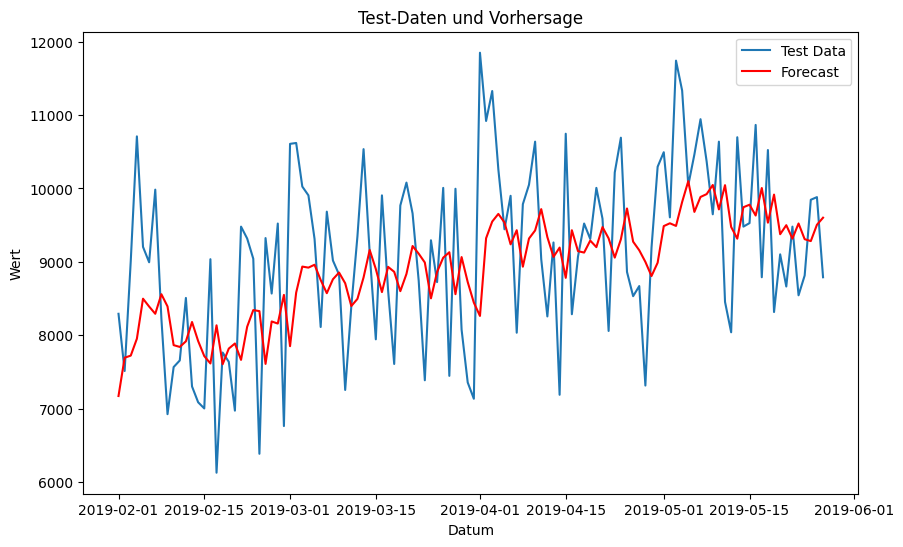

Model MAPE: 10.876854430491672%, Model MAE: 976.1474076873909, R2 Score: 0.07516592804559707


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

# Zeitreihe und Vorhersagen visualisieren

# plt.figure(figsize=(10, 6))
# plt.plot(df[0:to_row].index, training_data, label='Train Data')   #hier noch irgendwo ein Fehler
# plt.plot(df[to_row:].index, testing_data, label='Test Data')
# plt.plot(df[to_row:].index, model_predictions, label='Forecast', color='red')
# plt.title('Train und Test-Daten und Vorhersage')
# plt.xlabel('Datum')
# plt.ylabel('Wert')
# plt.legend()
# plt.show()

plt.figure(figsize=(10, 6))
plt.plot(df.index[to_row:], testing_data, label='Test Data')
plt.plot(df.index[to_row:], model_predictions, label='Forecast', color='red')
plt.title('Test-Daten und Vorhersage')
plt.xlabel('Datum')
plt.ylabel('Wert')
plt.legend()
plt.show()

print(f'Model MAPE: {mean_absolute_percentage_error(testing_data, model_predictions)* 100}%, Model MAE: {mean_absolute_error(testing_data, model_predictions)}, R2 Score: {r2_score(testing_data, model_predictions)}')


# Bester R2 bisher: 4%

## SARIMAX

Mean Squared Error: 3373046.1738001155


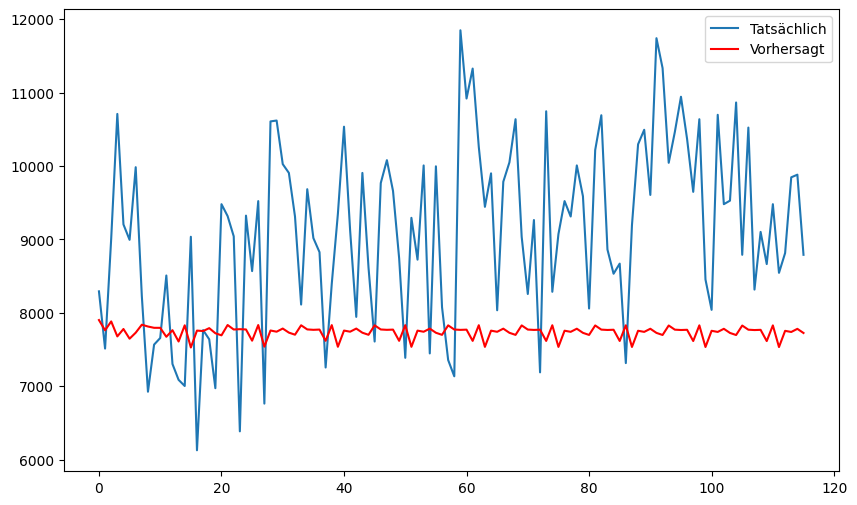

In [27]:
# SARIMAX Modellparameter festlegen (p, d, q, P, D, Q, s)
# Hier p, d, q sind für ARIMA-Teil und P, D, Q, s für den saisonalen Teil
order = (1, 1, 1)  # ARIMA order (p, d, q)
seasonal_order = (1, 1, 1, 12)  # Saisonaler Teil (P, D, Q, s), hier für jährliche Saisonalität

# SARIMAX-Modell auf den Trainingsdaten anpassen
model = SARIMAX(training_data, order=order, seasonal_order=seasonal_order, enforce_stationarity=False, enforce_invertibility=False)
model_fit = model.fit(disp=False)

# Vorhersagen mit dem Modell
predictions = model_fit.predict(start=len(training_data), end=len(training_data)+len(testing_data)-1, dynamic=False)

# Fehler berechnen
mse = mean_squared_error(testing_data, predictions)
print(f'Mean Squared Error: {mse}')

# Plotten der Ergebnisse
plt.figure(figsize=(10, 6))
plt.plot(testing_data, label='Tatsächlich')
plt.plot(predictions, color='red', label='Vorhersagt')
plt.legend()
plt.show()


# Analyse Predictions

In [51]:
display(arima_forecast)
hw_predictions.rename("hw_prediction", inplace=True)
display(hw_predictions)

2018-10-09    8950.670467
2018-10-10    9130.437287
2018-10-11    8907.233867
2018-10-12    8650.703031
2018-10-13    8730.559979
                 ...     
2019-05-23    8887.212719
2019-05-24    8887.212719
2019-05-25    8887.212719
2019-05-26    8887.212719
2019-05-27    8887.212719
Freq: D, Name: predicted_mean, Length: 231, dtype: float64

2018-10-09    8751.297404
2018-10-10    8511.434701
2018-10-11    8793.518106
2018-10-12    8641.702107
2018-10-13    8792.175644
                 ...     
2019-05-23    8935.056668
2019-05-24    8696.668743
2019-05-25    9068.113060
2019-05-26    8828.250357
2019-05-27    9110.333762
Freq: D, Name: hw_prediction, Length: 231, dtype: float64

# Berechnen von n_sby aus Calls

In [52]:
validation_df = df

validation_df = pd.merge(validation_df, hw_predictions, left_index=True, right_index=True)
validation_df = pd.merge(validation_df, arima_forecast, left_index=True, right_index=True)

In [53]:
#validation_df["total_personal"] = validation_df.apply(lambda row: (row.hw_prediction / 5), axis=1)
#validation_df["total_personal_based_on_orig_calls"] = validation_df.apply(lambda row: (row.calls / 5), axis=1)

#validation_df["sby_need_new"] = validation_df.apply(lambda row: row.total_personal - row.n_duty + row.n_sby , axis=1)
#validation_df["sby_need_based_on_orig_calls"] = validation_df.apply(lambda row: row.total_personal_based_on_orig_calls - row.n_duty + row.n_sby , axis=1)

In [54]:
validation_df.describe()

,n_sick,calls,n_duty,n_sby,sby_need,dafted,month,day_of_week,day_of_month,week_of_year,...,n_duty_ma_42_lag_30,dafted_ma_7_lag_30,dafted_ma_14_lag_30,dafted_ma_21_lag_30,dafted_ma_28_lag_30,dafted_ma_35_lag_30,dafted_ma_42_lag_30,season,hw_prediction,predicted_mean
count,231.000000,231.000000,231.0,231.0,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000,...,231.0,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000,231.000000
mean,75.718615,8473.532468,1900.0,90.0,53.554113,29.822511,5.917749,3.000000,15.852814,23.826840,...,1900.0,18.837353,19.576067,19.492063,18.875850,17.748547,16.895589,1.069264,8808.410631,8887.619701
std,12.031609,1297.897640,0.0,0.0,106.556967,77.076408,4.108018,2.004343,8.587401,17.872383,...,0.0,33.489054,28.333765,25.138310,22.563131,19.765914,17.979504,1.143777,154.221366,26.835810
min,49.000000,5760.000000,1900.0,90.0,0.000000,0.000000,1.000000,0.000000,1.000000,1.000000,...,1900.0,0.000000,0.000000,0.000000,0.000000,0.514286,0.428571,0.000000,8396.527595,8650.703031
25%,68.500000,7509.000000,1900.0,90.0,0.000000,0.000000,2.000000,1.000000,9.000000,9.000000,...,1900.0,0.000000,0.000000,1.166667,0.964286,1.285714,3.119048,0.000000,8702.971802,8887.212719
50%,75.000000,8502.000000,1900.0,90.0,0.000000,0.000000,4.000000,3.000000,16.000000,17.000000,...,1900.0,2.571429,8.071429,10.000000,9.928571,10.600000,10.071429,1.000000,8817.797251,8887.212719
75%,82.000000,9336.000000,1900.0,90.0,56.500000,0.000000,11.000000,5.000000,23.000000,44.000000,...,1900.0,26.857143,27.392857,25.333333,28.071429,27.342857,26.000000,1.000000,8919.740408,8887.212719
max,109.000000,11850.000000,1900.0,90.0,555.000000,465.000000,12.000000,6.000000,31.000000,52.000000,...,1900.0,182.714286,122.928571,97.238095,86.785714,72.542857,65.142857,3.000000,9110.333762,9130.437287


In [55]:
validation_df["calls_hw_diff"] = validation_df.apply(lambda row: (row.hw_prediction  - row.calls), axis=1)
validation_df["calls_arima_diff"] = validation_df.apply(lambda row: (row.predicted_mean  - row.calls), axis=1)

In [56]:
display(validation_df)

,n_sick,calls,n_duty,n_sby,sby_need,dafted,is_holiday,month,day_of_week,day_of_month,...,dafted_ma_14_lag_30,dafted_ma_21_lag_30,dafted_ma_28_lag_30,dafted_ma_35_lag_30,dafted_ma_42_lag_30,season,hw_prediction,predicted_mean,calls_hw_diff,calls_arima_diff
2018-10-09,97,9870.0,1900,90,171.0,81.0,False,10,1,9,...,66.571429,50.857143,41.642857,33.314286,28.785714,3,8751.297404,8950.670467,-1118.702596,-919.329533
2018-10-10,97,7896.0,1900,90,0.0,0.0,False,10,2,10,...,66.571429,50.857143,41.642857,33.314286,28.785714,3,8511.434701,9130.437287,615.434701,1234.437287
2018-10-11,103,7302.0,1900,90,0.0,0.0,False,10,3,11,...,66.642857,47.047619,38.178571,33.342857,28.809524,3,8793.518106,8907.233867,1491.518106,1605.233867
2018-10-12,106,7506.0,1900,90,0.0,0.0,False,10,4,12,...,68.285714,48.142857,39.000000,34.000000,29.357143,3,8641.702107,8650.703031,1135.702107,1144.703031
2018-10-13,93,9318.0,1900,90,57.0,0.0,False,10,5,13,...,68.285714,45.714286,39.000000,34.000000,29.357143,3,8792.175644,8730.559979,-525.824356,-587.440021
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-05-23,86,8544.0,1900,90,0.0,0.0,False,5,3,23,...,48.214286,64.380952,78.214286,68.571429,63.642857,1,8935.056668,8887.212719,391.056668,343.212719
2019-05-24,81,8814.0,1900,90,0.0,0.0,False,5,4,24,...,50.642857,58.904762,86.785714,72.542857,64.880952,1,8696.668743,8887.212719,-117.331257,73.212719
2019-05-25,76,9846.0,1900,90,146.0,56.0,False,5,5,25,...,50.642857,52.380952,83.285714,72.000000,64.880952,1,9068.113060,8887.212719,-777.886940,-958.787281
2019-05-26,83,9882.0,1900,90,160.0,70.0,False,5,6,26,...,50.642857,52.380952,83.285714,72.000000,64.880952,1,8828.250357,8887.212719,-1053.749643,-994.787281


In [57]:
display(validation_df.sort_values("sby_need", ascending=False))

,n_sick,calls,n_duty,n_sby,sby_need,dafted,is_holiday,month,day_of_week,day_of_month,...,dafted_ma_14_lag_30,dafted_ma_21_lag_30,dafted_ma_28_lag_30,dafted_ma_35_lag_30,dafted_ma_42_lag_30,season,hw_prediction,predicted_mean,calls_hw_diff,calls_arima_diff
2019-04-01,85,11850.0,1900,90,555.0,465.0,False,4,0,1,...,27.571429,18.380952,23.714286,18.971429,15.809524,1,9032.631874,8887.212719,-2817.368126,-2962.787281
2019-05-03,74,11742.0,1900,90,523.0,433.0,False,5,4,3,...,93.000000,70.857143,60.071429,63.085714,52.571429,1,9076.984746,8887.212719,-2665.015254,-2854.787281
2019-04-03,79,11328.0,1900,90,445.0,355.0,False,4,2,3,...,37.571429,25.047619,21.214286,22.971429,19.142857,1,8751.099218,8887.212719,-2576.900782,-2440.787281
2019-05-04,66,11334.0,1900,90,433.0,343.0,False,5,5,4,...,101.428571,77.380952,64.750000,67.000000,55.833333,1,8925.168747,8887.212719,-2408.831253,-2446.787281
2019-05-07,78,10944.0,1900,90,367.0,277.0,False,5,1,7,...,104.785714,77.380952,66.428571,55.000000,56.952381,1,9082.655398,8887.212719,-1861.344602,-2056.787281
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-05-17,88,8790.0,1900,90,0.0,0.0,False,5,4,17,...,54.214286,92.952381,73.607143,64.200000,58.119048,1,9092.316791,8887.212719,302.316791,97.212719
2019-05-23,86,8544.0,1900,90,0.0,0.0,False,5,3,23,...,48.214286,64.380952,78.214286,68.571429,63.642857,1,8935.056668,8887.212719,391.056668,343.212719
2019-05-21,66,8664.0,1900,90,0.0,0.0,False,5,1,21,...,47.857143,92.809524,76.321429,65.571429,60.238095,1,8817.797251,8887.212719,153.797251,223.212719
2019-05-24,81,8814.0,1900,90,0.0,0.0,False,5,4,24,...,50.642857,58.904762,86.785714,72.542857,64.880952,1,8696.668743,8887.212719,-117.331257,73.212719


In [106]:
# validation_df["sby_need"] = validation_df.apply(lambda row: (row.total_personal - (row.n_duty + row.n_sick)), axis=1)

## Single prediction

In [107]:
predict_data = pd.DataFrame([{
        'month' : 9,
        'day_of_week' : 3,
        'season' : 3,
        'n_sby_ma_35_lag_28' : 67,
        'day_of_year' : 266,
    }])


best_model.predict(predict_data)

ValueError: The feature names should match those that were passed during fit.
Feature names unseen at fit time:
- day_of_year
- n_sby_ma_35_lag_28
- season
Feature names seen at fit time, yet now missing:
- day_of_month


# Export model

In [ ]:
import joblib

# Modell speichern
joblib.dump(best_model, '../../app/models/readiness_model.pkl')

['../../app/models/readiness_model.pkl']

In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_train)